# EcoPulse AI — Phase 2

## 1. Project Introduction

**Project:** EcoPulse AI
**Full title:** Intelligent Energy Consumption Monitoring, Forecasting and Anomaly Detection System
**Tagline:** *Understand Energy. Predict Tomorrow. Optimise Smarter.*

This notebook is the exploratory data analysis (EDA) deliverable for Phase 2. It
profiles the raw UCI household electricity dataset before any cleaning or
modelling. The purpose is to establish what the data contains, where it is
incomplete, and which characteristics later forecasting and anomaly-detection
work must respect.

**Scope rules for this notebook**

- The raw file is read-only and remains unchanged.
- Missing values are described, never imputed or replaced with zero.
- Outliers are retained; none are removed or capped.
- No features are normalised or standardised.
- No machine-learning, forecasting or anomaly-detection model is trained.
- Figures are exploratory descriptions, not production analytics.

All statistics and findings below are computed from the actual dataset.

## 2. Dataset Information

| Item | Detail |
| --- | --- |
| Dataset | Individual Household Electric Power Consumption |
| Source | [UCI Machine Learning Repository, dataset 235](https://archive.ics.uci.edu/dataset/235/individual+household+electric+power+consumption) |
| Local file | `data/raw/household_power_consumption.txt` |
| Licence | CC BY 4.0 (UCI Machine Learning Repository) |
| Coverage | December 2006 to November 2010 |
| Frequency | Approximately one reading per minute |
| Location | One household in Sceaux, France |
| Rows / columns | Approximately 2.08 million rows and 9 original columns |
| Missing marker | `?` in the raw text file |
| Units | Active and reactive power in kW; voltage in V; current in A; sub-metering in Wh per minute |

**Original columns:** `Date`, `Time`, `Global_active_power`,
`Global_reactive_power`, `Voltage`, `Global_intensity`, `Sub_metering_1`,
`Sub_metering_2`, `Sub_metering_3`.

For one-minute readings, `Global_active_power / 60` approximates energy in kWh
for that minute. Sub-metering values are watt-hours for the minute, so dividing
by 1000 gives kWh. Missing readings are excluded from energy calculations rather
than treated as zero.

## 3. Import Libraries

Pandas and NumPy handle loading and aggregation, Matplotlib and Seaborn produce
the figures, and `pathlib` keeps paths independent of the working directory.

In [1]:
from __future__ import annotations

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update(
    {
        "figure.figsize": (12, 5),
        "figure.dpi": 110,
        "axes.titleweight": "bold",
        "axes.titlesize": 13,
        "axes.labelsize": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
pd.options.display.max_columns = 20
pd.options.display.float_format = "{:,.4f}".format

## 4. Load Dataset

The loader uses the semicolon delimiter and maps `?` to `NaN`. It then coerces
the seven measurement columns to numeric. No row is dropped.

In [2]:
def find_project_root() -> Path:
    """Find the repository root from the notebook or Jupyter working directory."""
    start = Path.cwd().resolve()
    for candidate in (start, *start.parents):
        if (candidate / "data" / "raw" / "household_power_consumption.txt").exists():
            return candidate
    raise FileNotFoundError(
        "Could not find data/raw/household_power_consumption.txt. "
        "Open this notebook from inside the EcoPulse-AI repository."
    )


PROJECT_ROOT = find_project_root()
DATASET_PATH = PROJECT_ROOT / "data" / "raw" / "household_power_consumption.txt"
REPORT_DIR = PROJECT_ROOT / "reports" / "eda"
FIGURE_DIR = REPORT_DIR / "figures"
REPORT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

NUMERIC_COLUMNS = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3",
]
SUB_METERING_COLUMNS = ["Sub_metering_1", "Sub_metering_2", "Sub_metering_3"]
TIMESTAMP_FORMAT = "%d/%m/%Y %H:%M:%S"


def format_bytes(value: int) -> str:
    """Return a compact, human-readable byte size."""
    size = float(value)
    for unit in ("B", "KB", "MB", "GB"):
        if size < 1024:
            return f"{size:,.2f} {unit}"
        size /= 1024
    return f"{size:,.2f} TB"


def save_and_show(fig: plt.Figure, filename: str) -> None:
    """Save a figure to reports/eda/figures and display it in the notebook."""
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / filename, dpi=150, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)


print(f"Project root: {PROJECT_ROOT}")
print(f"Dataset:      {DATASET_PATH}")
print(f"Reports:      {REPORT_DIR}")
print(f"Figures:      {FIGURE_DIR}")

Project root: D:\ai\EcoPulse-AI
Dataset:      D:\ai\EcoPulse-AI\data\raw\household_power_consumption.txt
Reports:      D:\ai\EcoPulse-AI\reports\eda
Figures:      D:\ai\EcoPulse-AI\reports\eda\figures


In [3]:
if not DATASET_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATASET_PATH}")

df = pd.read_csv(
    DATASET_PATH,
    sep=";",
    na_values=["?"],
    keep_default_na=True,
    low_memory=False,
)

for column in NUMERIC_COLUMNS:
    df[column] = pd.to_numeric(df[column], errors="coerce")

timestamps = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    format=TIMESTAMP_FORMAT,
    errors="coerce",
)
valid_timestamps = timestamps.dropna()

print(f"Loaded {len(df):,} rows x {df.shape[1]} columns")
print(f"File size: {format_bytes(DATASET_PATH.stat().st_size)}")
print("The raw file is unchanged. '?' values are NaN; no value was imputed.")

Loaded 2,075,259 rows x 9 columns
File size: 126.80 MB
The raw file is unchanged. '?' values are NaN; no value was imputed.


## 5. Dataset Dimensions

In [4]:
print(f"Rows:                        {len(df):,}")
print(f"Columns:                     {df.shape[1]:,}")
print(f"Dataset shape:               {df.shape}")
print(f"Rows with any missing value: {int(df.isna().any(axis=1).sum()):,}")
print(f"Complete rows:               {int(df.notna().all(axis=1).sum()):,}")
print(f"Memory usage (deep):         {format_bytes(int(df.memory_usage(deep=True).sum()))}")

Rows:                        2,075,259
Columns:                     9
Dataset shape:               (2075259, 9)


Rows with any missing value: 25,979


Complete rows:               2,049,280


Memory usage (deep):         338.33 MB


## 6. Column Information

`DataFrame.info` confirms the non-null counts, dtypes, and memory footprint of the
loaded frame.

In [5]:
df.info(verbose=True, show_counts=True, memory_usage="deep")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 9 columns):
 #   Column                 Non-Null Count    Dtype  
---  ------                 --------------    -----  
 0   Date                   2075259 non-null  object 
 1   Time                   2075259 non-null  object 
 2   Global_active_power    2049280 non-null  float64
 3   Global_reactive_power  2049280 non-null  float64
 4   Voltage                2049280 non-null  float64
 5   Global_intensity       2049280 non-null  float64
 6   Sub_metering_1         2049280 non-null  float64
 7   Sub_metering_2         2049280 non-null  float64
 8   Sub_metering_3         2049280 non-null  float64
dtypes: float64(7), object(2)
memory usage: 338.3 MB


## 7. Data Types

The raw text columns `Date` and `Time` remain text until timestamps are parsed.
All seven measurement columns are floating-point values after coercion.

In [6]:
dtype_table = pd.DataFrame(
    {
        "Column": df.columns,
        "Pandas dtype": df.dtypes.astype(str).to_numpy(),
        "Non-null values": df.notna().sum().to_numpy(),
    }
)
display(dtype_table)

memory = df.memory_usage(deep=True).drop("Index", errors="ignore")
display(
    pd.DataFrame(
        {
            "Column": memory.index,
            "Memory": [format_bytes(int(value)) for value in memory.values],
        }
    )
)

,Column,Pandas dtype,Non-null values
0,Date,object,2075259
1,Time,object,2075259
2,Global_active_power,float64,2049280
3,Global_reactive_power,float64,2049280
4,Voltage,float64,2049280
5,Global_intensity,float64,2049280
6,Sub_metering_1,float64,2049280
7,Sub_metering_2,float64,2049280
8,Sub_metering_3,float64,2049280


,Column,Memory
0,Date,114.69 MB
1,Time,112.81 MB
2,Global_active_power,15.83 MB
3,Global_reactive_power,15.83 MB
4,Voltage,15.83 MB
5,Global_intensity,15.83 MB
6,Sub_metering_1,15.83 MB
7,Sub_metering_2,15.83 MB
8,Sub_metering_3,15.83 MB


## 8. First and Last Records

The first records show the raw layout and the last records confirm the end of the
observation window. Both samples are displayed exactly as loaded.

In [7]:
print("First 10 records")
display(df.head(10))

print("Last 10 records")
display(df.tail(10))

First 10 records


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.2160,0.4180,234.8400,18.4000,0.0000,1.0000,17.0000
1,16/12/2006,17:25:00,5.3600,0.4360,233.6300,23.0000,0.0000,1.0000,16.0000
2,16/12/2006,17:26:00,5.3740,0.4980,233.2900,23.0000,0.0000,2.0000,17.0000
3,16/12/2006,17:27:00,5.3880,0.5020,233.7400,23.0000,0.0000,1.0000,17.0000
4,16/12/2006,17:28:00,3.6660,0.5280,235.6800,15.8000,0.0000,1.0000,17.0000
5,16/12/2006,17:29:00,3.5200,0.5220,235.0200,15.0000,0.0000,2.0000,17.0000
6,16/12/2006,17:30:00,3.7020,0.5200,235.0900,15.8000,0.0000,1.0000,17.0000
7,16/12/2006,17:31:00,3.7000,0.5200,235.2200,15.8000,0.0000,1.0000,17.0000
8,16/12/2006,17:32:00,3.6680,0.5100,233.9900,15.8000,0.0000,1.0000,17.0000
9,16/12/2006,17:33:00,3.6620,0.5100,233.8600,15.8000,0.0000,2.0000,16.0000


Last 10 records


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
2075249,26/11/2010,20:53:00,0.9440,0.0000,238.7200,4.0000,0.0000,0.0000,0.0000
2075250,26/11/2010,20:54:00,0.9460,0.0000,239.3100,4.0000,0.0000,0.0000,0.0000
2075251,26/11/2010,20:55:00,0.9460,0.0000,239.7400,4.0000,0.0000,0.0000,0.0000
2075252,26/11/2010,20:56:00,0.9420,0.0000,239.4100,4.0000,0.0000,0.0000,0.0000
2075253,26/11/2010,20:57:00,0.9460,0.0000,240.3300,4.0000,0.0000,0.0000,0.0000
2075254,26/11/2010,20:58:00,0.9460,0.0000,240.4300,4.0000,0.0000,0.0000,0.0000
2075255,26/11/2010,20:59:00,0.9440,0.0000,240.0000,4.0000,0.0000,0.0000,0.0000
2075256,26/11/2010,21:00:00,0.9380,0.0000,239.8200,3.8000,0.0000,0.0000,0.0000
2075257,26/11/2010,21:01:00,0.9340,0.0000,239.7000,3.8000,0.0000,0.0000,0.0000
2075258,26/11/2010,21:02:00,0.9320,0.0000,239.5500,3.8000,0.0000,0.0000,0.0000


## 9. Missing Values Analysis

Missing counts are calculated per column. A missing reading is unknown energy,
not a measured zero, so nothing is filled here.

In [8]:
missing_table = pd.DataFrame(
    {
        "Column": df.columns,
        "Total Records": len(df),
        "Missing Values": df.isna().sum().to_numpy(),
        "Non-Missing Values": df.notna().sum().to_numpy(),
        "Missing Percentage": (df.isna().mean() * 100).round(4).to_numpy(),
    }
)
display(missing_table)

rows_with_missing = int(df.isna().any(axis=1).sum())
rows_all_numeric_missing = int(df[NUMERIC_COLUMNS].isna().all(axis=1).sum())
print(f"Total missing cells: {int(df.isna().sum().sum()):,}")
print(f"Rows with any missing value: {rows_with_missing:,}")
print(f"Rows where all seven measurements are missing: {rows_all_numeric_missing:,}")
print(f"Rows with partial numeric missingness: "
      f"{rows_with_missing - rows_all_numeric_missing:,}")

,Column,Total Records,Missing Values,Non-Missing Values,Missing Percentage
0,Date,2075259,0,2075259,0.0000
1,Time,2075259,0,2075259,0.0000
2,Global_active_power,2075259,25979,2049280,1.2518
3,Global_reactive_power,2075259,25979,2049280,1.2518
4,Voltage,2075259,25979,2049280,1.2518
5,Global_intensity,2075259,25979,2049280,1.2518
6,Sub_metering_1,2075259,25979,2049280,1.2518
7,Sub_metering_2,2075259,25979,2049280,1.2518
8,Sub_metering_3,2075259,25979,2049280,1.2518


Total missing cells: 181,853
Rows with any missing value: 25,979
Rows where all seven measurements are missing: 25,979
Rows with partial numeric missingness: 0


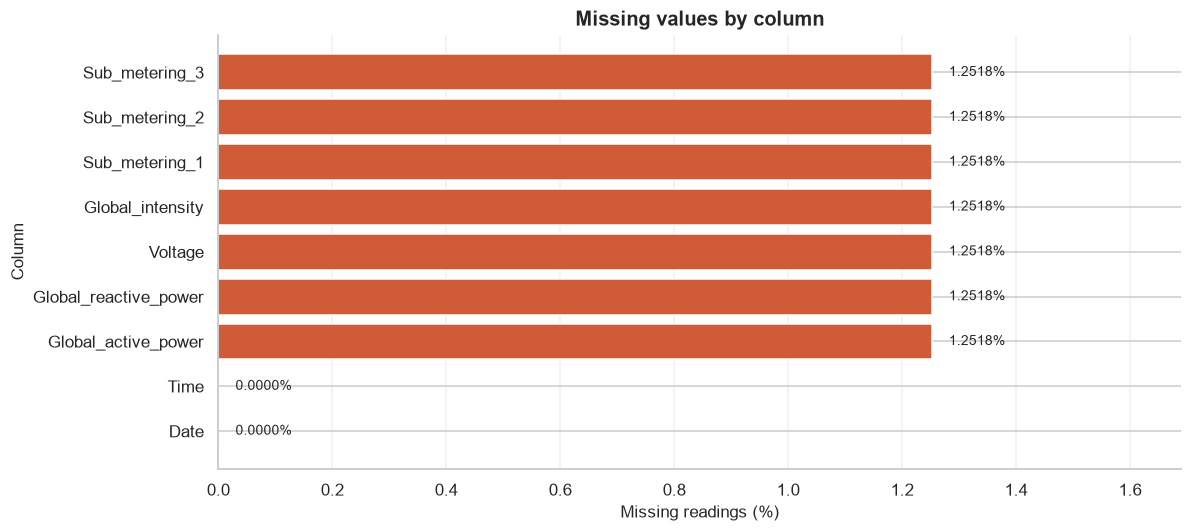

In [9]:
missing_pct = (df.isna().mean() * 100).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(11, 5))
colors = ["#cf5c36" if value > 0 else "#8fa6a6" for value in missing_pct.values]
bars = ax.barh(missing_pct.index, missing_pct.values, color=colors)
for bar, value in zip(bars, missing_pct.values, strict=True):
    ax.text(
        value + 0.03,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.4f}%",
        va="center",
        fontsize=9,
    )
ax.set_xlim(0, max(float(missing_pct.max()) * 1.35, 0.5))
ax.set_xlabel("Missing readings (%)")
ax.set_ylabel("Column")
ax.set_title("Missing values by column")
ax.grid(axis="x", alpha=0.3)
save_and_show(fig, "09_missing_values.png")

**Observation.** All seven measurement columns share exactly the same missing
mask, so missingness occurs as whole-reading gaps across all measurements at the
same timestamps. The `Date` and `Time` columns are complete.

## 10. Duplicate Records Analysis

Complete-row duplicates and duplicate valid timestamps are checked separately.
Invalid (unparseable) timestamps are counted but excluded from the timestamp
duplicate count, as required by Phase 2.

In [10]:
duplicate_rows = int(df.duplicated().sum())
duplicate_timestamps = int(valid_timestamps.duplicated().sum())
invalid_timestamps = int(timestamps.isna().sum())

duplicate_table = pd.DataFrame(
    {
        "Metric": [
            "Total records",
            "Duplicate complete rows",
            "Total valid timestamps",
            "Duplicate valid timestamps",
            "Invalid timestamps",
        ],
        "Value": [
            len(df),
            duplicate_rows,
            len(valid_timestamps),
            duplicate_timestamps,
            invalid_timestamps,
        ],
    }
)
display(duplicate_table)

if duplicate_rows:
    display(df[df.duplicated(keep=False)].sort_values(["Date", "Time"]).head(20))
else:
    print("No complete duplicate rows to display.")

,Metric,Value
0,Total records,2075259
1,Duplicate complete rows,0
2,Total valid timestamps,2075259
3,Duplicate valid timestamps,0
4,Invalid timestamps,0


No complete duplicate rows to display.


## 11. Date and Time Analysis

The observation window, one-minute grid coverage, gaps, and annual record counts
are computed from the parsed timestamps.

In [11]:
first_ts = valid_timestamps.min()
last_ts = valid_timestamps.max()
duration = last_ts - first_ts
expected_slots = int(duration.total_seconds() // 60) + 1
grid_coverage = len(valid_timestamps) / expected_slots * 100

print(f"Timestamp format:           {TIMESTAMP_FORMAT}")
print(f"Invalid timestamps:         {invalid_timestamps:,}")
print(f"Earliest valid timestamp:   {first_ts}")
print(f"Latest valid timestamp:     {last_ts}")
print(f"Observed duration:          {duration} ({duration.total_seconds() / 86_400:,.2f} days)")
print(f"Expected one-minute slots:  {expected_slots:,}")
print(f"Grid coverage:              {grid_coverage:.4f}%")

readings_by_year = (
    valid_timestamps.dt.year.value_counts()
    .sort_index()
    .rename_axis("Year")
    .to_frame("Readings")
)
fully_missing = df[NUMERIC_COLUMNS].isna().all(axis=1)
readings_by_year["Fully Missing Measurements"] = (
    fully_missing.groupby(valid_timestamps.dt.year).sum().astype(int)
)
display(readings_by_year)

intervals = valid_timestamps.sort_values().diff().dropna()
gap_count = int((intervals.dt.total_seconds() > 60).sum())
print(f"Minimum interval: {intervals.min()}")
print(f"Maximum interval: {intervals.max()}")
print(f"Intervals longer than one minute: {gap_count:,}")
display(intervals.value_counts().head(5).rename_axis("Interval").to_frame("Count"))

Timestamp format:           %d/%m/%Y %H:%M:%S
Invalid timestamps:         0
Earliest valid timestamp:   2006-12-16 17:24:00
Latest valid timestamp:     2010-11-26 21:02:00
Observed duration:          1441 days 03:38:00 (1,441.15 days)
Expected one-minute slots:  2,075,259
Grid coverage:              100.0000%


,Readings,Fully Missing Measurements
Year,,
2006,21996,4
2007,525600,3931
2008,527040,135
2009,525600,4280
2010,475023,17629


Minimum interval: 0 days 00:01:00
Maximum interval: 0 days 00:01:00
Intervals longer than one minute: 0


,Count
Interval,
0 days 00:01:00,2075258


**Timestamp observations.** The valid timestamps form a complete one-minute grid
over the observed range. The raw timestamps contain no UTC offset; they are local
civil time in France. A later ETL phase must make an explicit Europe/Paris to UTC
decision and validate daylight-saving transitions.

## 12. Numerical Statistical Summary

The summary below uses only the seven measurement columns and pairwise-valid
observations. The count differs from the row count because the missing readings
are not imputed.

In [12]:
summary = df[NUMERIC_COLUMNS].describe(percentiles=[0.25, 0.5, 0.75]).T
summary = summary.rename(
    columns={
        "count": "Count",
        "mean": "Mean",
        "std": "Standard Deviation",
        "min": "Minimum",
        "25%": "25th Percentile",
        "50%": "Median",
        "75%": "75th Percentile",
        "max": "Maximum",
    }
)
summary.index.name = "Column"
summary["Count"] = summary["Count"].astype(int)
display(summary.round(4))

,Count,Mean,Standard Deviation,Minimum,25th Percentile,Median,75th Percentile,Maximum
Column,,,,,,,,
Global_active_power,2049280,1.0916,1.0573,0.0760,0.3080,0.6020,1.5280,11.1220
Global_reactive_power,2049280,0.1237,0.1127,0.0000,0.0480,0.1000,0.1940,1.3900
Voltage,2049280,240.8399,3.2400,223.2000,238.9900,241.0100,242.8900,254.1500
Global_intensity,2049280,4.6278,4.4444,0.2000,1.4000,2.6000,6.4000,48.4000
Sub_metering_1,2049280,1.1219,6.1530,0.0000,0.0000,0.0000,0.0000,88.0000
Sub_metering_2,2049280,1.2985,5.8220,0.0000,0.0000,0.0000,1.0000,80.0000
Sub_metering_3,2049280,6.4584,8.4372,0.0000,0.0000,1.0000,17.0000,31.0000


## 13. Global Active Power Analysis

`Global_active_power` is the whole-house active power averaged over each minute,
in kW. The histogram axis is clipped at the 99.5th percentile for readability;
the printed statistics and the full range remain based on every valid reading.

Valid readings:       2,049,280
Mean:                 1.0916 kW
Median:               0.6020 kW
Standard deviation:   1.0573 kW
Minimum:              0.0760 kW
Maximum:              11.1220 kW
Skewness:             1.7862
99.5th percentile:    5.5180 kW
Readings above clip:  10,235 (0.50%)


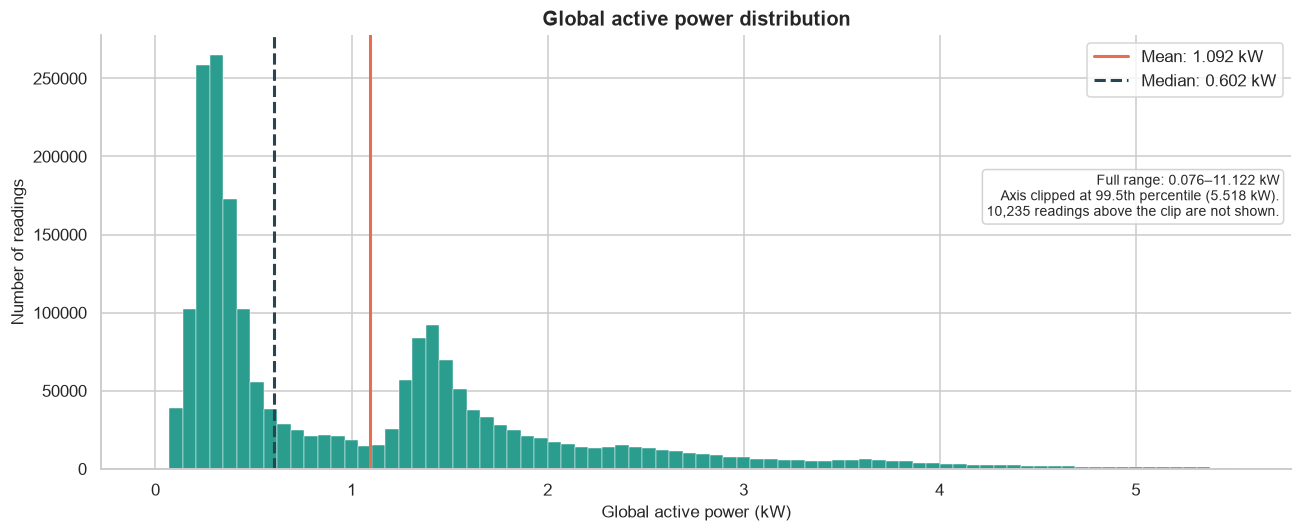

In [13]:
active = df["Global_active_power"]
active_valid = active.dropna()
active_mean = float(active_valid.mean())
active_median = float(active_valid.median())
active_upper = float(active_valid.quantile(0.995))
active_clipped = int((active_valid > active_upper).sum())

print(f"Valid readings:       {len(active_valid):,}")
print(f"Mean:                 {active_mean:,.4f} kW")
print(f"Median:               {active_median:,.4f} kW")
print(f"Standard deviation:   {active_valid.std():,.4f} kW")
print(f"Minimum:              {active_valid.min():,.4f} kW")
print(f"Maximum:              {active_valid.max():,.4f} kW")
print(f"Skewness:             {active_valid.skew():,.4f}")
print(f"99.5th percentile:    {active_upper:,.4f} kW")
print(f"Readings above clip:  {active_clipped:,} ({active_clipped / len(active_valid) * 100:.2f}%)")

fig, ax = plt.subplots(figsize=(12, 5))
ax.hist(
    active_valid,
    bins=80,
    range=(0, active_upper),
    color="#2a9d8f",
    edgecolor="white",
    linewidth=0.3,
)
ax.axvline(active_mean, color="#e76f51", linewidth=2, label=f"Mean: {active_mean:.3f} kW")
ax.axvline(
    active_median,
    color="#264653",
    linewidth=2,
    linestyle="--",
    label=f"Median: {active_median:.3f} kW",
)
ax.set_xlabel("Global active power (kW)")
ax.set_ylabel("Number of readings")
ax.set_title("Global active power distribution")
ax.legend(loc="upper right")
ax.text(
    0.99,
    0.68,
    f"Full range: {active_valid.min():.3f}–{active_valid.max():.3f} kW\n"
    f"Axis clipped at 99.5th percentile ({active_upper:.3f} kW).\n"
    f"{active_clipped:,} readings above the clip are not shown.",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=9,
    bbox={"boxstyle": "round", "facecolor": "white", "alpha": 0.85, "edgecolor": "#cccccc"},
)
save_and_show(fig, "13_global_active_power_distribution.png")

**Observation.** Active power is strongly right-skewed: most minutes sit well below
the mean, with a long tail of high-consumption periods. That shape matters for
later scaling, loss functions and anomaly thresholds.

## 14. Global Reactive Power Analysis

Reactive power is recorded in kVAr-equivalent kW units in this dataset. It is
smaller than active power and has a large mass at exactly zero.

Valid readings:       2,049,280
Mean:                 0.1237
Median:               0.1000
Standard deviation:   0.1127
Minimum:              0.0000
Maximum:              1.3900
Zero readings:        481,561 (23.50%)


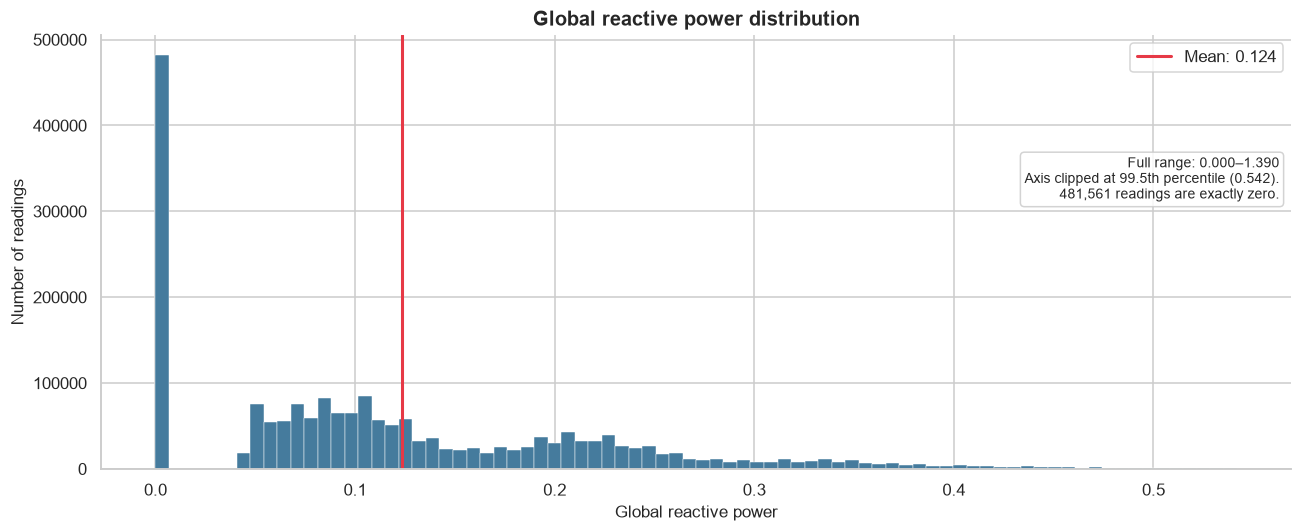

In [14]:
reactive = df["Global_reactive_power"]
reactive_valid = reactive.dropna()
reactive_upper = float(reactive_valid.quantile(0.995))
reactive_zeros = int((reactive_valid == 0).sum())

print(f"Valid readings:       {len(reactive_valid):,}")
print(f"Mean:                 {reactive_valid.mean():,.4f}")
print(f"Median:               {reactive_valid.median():,.4f}")
print(f"Standard deviation:   {reactive_valid.std():,.4f}")
print(f"Minimum:              {reactive_valid.min():,.4f}")
print(f"Maximum:              {reactive_valid.max():,.4f}")
print(f"Zero readings:        {reactive_zeros:,} ({reactive_zeros / len(reactive_valid) * 100:.2f}%)")

fig, ax = plt.subplots(figsize=(12, 5))
ax.hist(
    reactive_valid,
    bins=80,
    range=(0, reactive_upper),
    color="#457b9d",
    edgecolor="white",
    linewidth=0.3,
)
ax.axvline(
    float(reactive_valid.mean()),
    color="#e63946",
    linewidth=2,
    label=f"Mean: {reactive_valid.mean():.3f}",
)
ax.set_xlabel("Global reactive power")
ax.set_ylabel("Number of readings")
ax.set_title("Global reactive power distribution")
ax.legend(loc="upper right")
ax.text(
    0.99,
    0.72,
    f"Full range: {reactive_valid.min():.3f}–{reactive_valid.max():.3f}\n"
    f"Axis clipped at 99.5th percentile ({reactive_upper:.3f}).\n"
    f"{reactive_zeros:,} readings are exactly zero.",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=9,
    bbox={"boxstyle": "round", "facecolor": "white", "alpha": 0.85, "edgecolor": "#cccccc"},
)
save_and_show(fig, "14_global_reactive_power_distribution.png")

## 15. Voltage Analysis

Voltage stays within a narrow band around 240 V, which is consistent with the
French low-voltage supply. It is a useful sanity-check signal, not an energy
measurement.

Valid readings:       2,049,280
Mean:                 240.8399 V
Median:               241.0100 V
Standard deviation:   3.2400 V
Minimum:              223.2000 V
Maximum:              254.1500 V


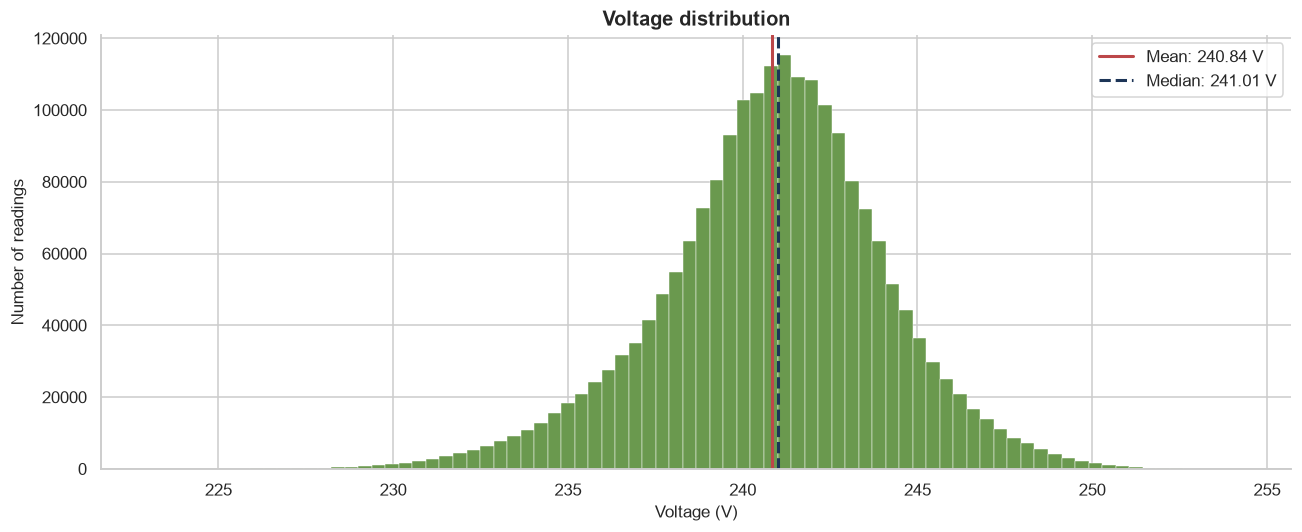

In [15]:
voltage = df["Voltage"]
voltage_valid = voltage.dropna()

print(f"Valid readings:       {len(voltage_valid):,}")
print(f"Mean:                 {voltage_valid.mean():,.4f} V")
print(f"Median:               {voltage_valid.median():,.4f} V")
print(f"Standard deviation:   {voltage_valid.std():,.4f} V")
print(f"Minimum:              {voltage_valid.min():,.4f} V")
print(f"Maximum:              {voltage_valid.max():,.4f} V")

fig, ax = plt.subplots(figsize=(12, 5))
ax.hist(
    voltage_valid,
    bins=80,
    color="#6a994e",
    edgecolor="white",
    linewidth=0.3,
)
ax.axvline(
    float(voltage_valid.mean()),
    color="#bc4749",
    linewidth=2,
    label=f"Mean: {voltage_valid.mean():.2f} V",
)
ax.axvline(
    float(voltage_valid.median()),
    color="#1d3557",
    linewidth=2,
    linestyle="--",
    label=f"Median: {voltage_valid.median():.2f} V",
)
ax.set_xlabel("Voltage (V)")
ax.set_ylabel("Number of readings")
ax.set_title("Voltage distribution")
ax.legend(loc="upper right")
save_and_show(fig, "15_voltage_distribution.png")

## 16. Global Intensity Analysis

`Global_intensity` is current in amperes. Because it is derived from power and
voltage, we expect a very strong relationship with active power; the correlation
section confirms it quantitatively.

Valid readings:       2,049,280
Mean:                 4.6278 A
Median:               2.6000 A
Standard deviation:   4.4444 A
Minimum:              0.2000 A
Maximum:              48.4000 A
99.5th percentile:    23.6000 A


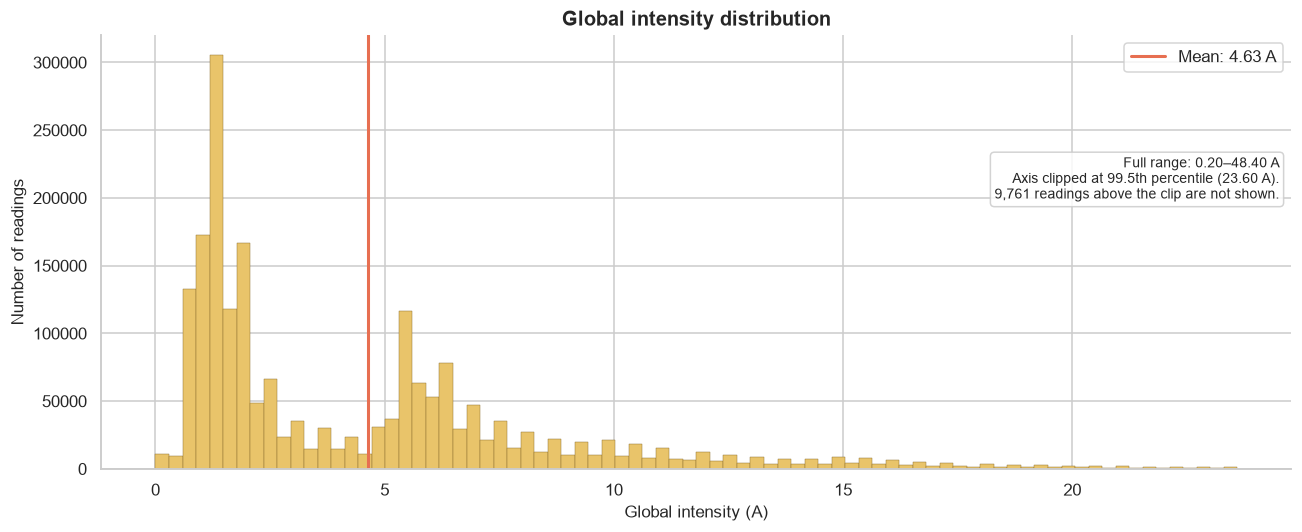

In [16]:
intensity = df["Global_intensity"]
intensity_valid = intensity.dropna()
intensity_upper = float(intensity_valid.quantile(0.995))
intensity_clipped = int((intensity_valid > intensity_upper).sum())

print(f"Valid readings:       {len(intensity_valid):,}")
print(f"Mean:                 {intensity_valid.mean():,.4f} A")
print(f"Median:               {intensity_valid.median():,.4f} A")
print(f"Standard deviation:   {intensity_valid.std():,.4f} A")
print(f"Minimum:              {intensity_valid.min():,.4f} A")
print(f"Maximum:              {intensity_valid.max():,.4f} A")
print(f"99.5th percentile:    {intensity_upper:,.4f} A")

fig, ax = plt.subplots(figsize=(12, 5))
ax.hist(
    intensity_valid,
    bins=80,
    range=(0, intensity_upper),
    color="#e9c46a",
    edgecolor="#8d6e2f",
    linewidth=0.3,
)
ax.axvline(
    float(intensity_valid.mean()),
    color="#e76f51",
    linewidth=2,
    label=f"Mean: {intensity_valid.mean():.2f} A",
)
ax.set_xlabel("Global intensity (A)")
ax.set_ylabel("Number of readings")
ax.set_title("Global intensity distribution")
ax.legend(loc="upper right")
ax.text(
    0.99,
    0.72,
    f"Full range: {intensity_valid.min():.2f}–{intensity_valid.max():.2f} A\n"
    f"Axis clipped at 99.5th percentile ({intensity_upper:.2f} A).\n"
    f"{intensity_clipped:,} readings above the clip are not shown.",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=9,
    bbox={"boxstyle": "round", "facecolor": "white", "alpha": 0.85, "edgecolor": "#cccccc"},
)
save_and_show(fig, "16_global_intensity_distribution.png")

## 17. Sub Metering Analysis

The three sub-meters cover specific circuits: kitchen, laundry room, and
water-heater/air-conditioning. Values are watt-hours per minute, so total energy
is `sum / 1000` kWh. Zero values are valid idle periods, not missing data.

In [17]:
sub_kwh = df[SUB_METERING_COLUMNS].sum() / 1000
global_kwh = float(df["Global_active_power"].sum() / 60)
sub_share = sub_kwh / global_kwh * 100
zero_share = (
    df[SUB_METERING_COLUMNS].eq(0).sum()
    / df[SUB_METERING_COLUMNS].notna().sum()
    * 100
)

sub_table = pd.DataFrame(
    {
        "Total energy (kWh)": sub_kwh.round(2),
        "Share of whole-house (%)": sub_share.round(2),
        "Zero readings (%)": zero_share.round(2),
    }
)
display(sub_table)

unmetered_kwh = global_kwh - float(sub_kwh.sum())
print(f"Sub-metered total:  {sub_kwh.sum():,.2f} kWh")
print(f"Whole-house total:  {global_kwh:,.2f} kWh")
print(f"Unmetered balance:  {unmetered_kwh:,.2f} kWh")
print(f"Sub-metered share:  {sub_kwh.sum() / global_kwh * 100:.2f}%")

,Total energy (kWh),Share of whole-house (%),Zero readings (%)
Sub_metering_1,"2,299.1400",6.1700,91.7500
Sub_metering_2,"2,661.0300",7.1400,70.1100
Sub_metering_3,"13,235.1700",35.5000,41.5800


Sub-metered total:  18,195.33 kWh
Whole-house total:  37,283.75 kWh
Unmetered balance:  19,088.41 kWh
Sub-metered share:  48.80%


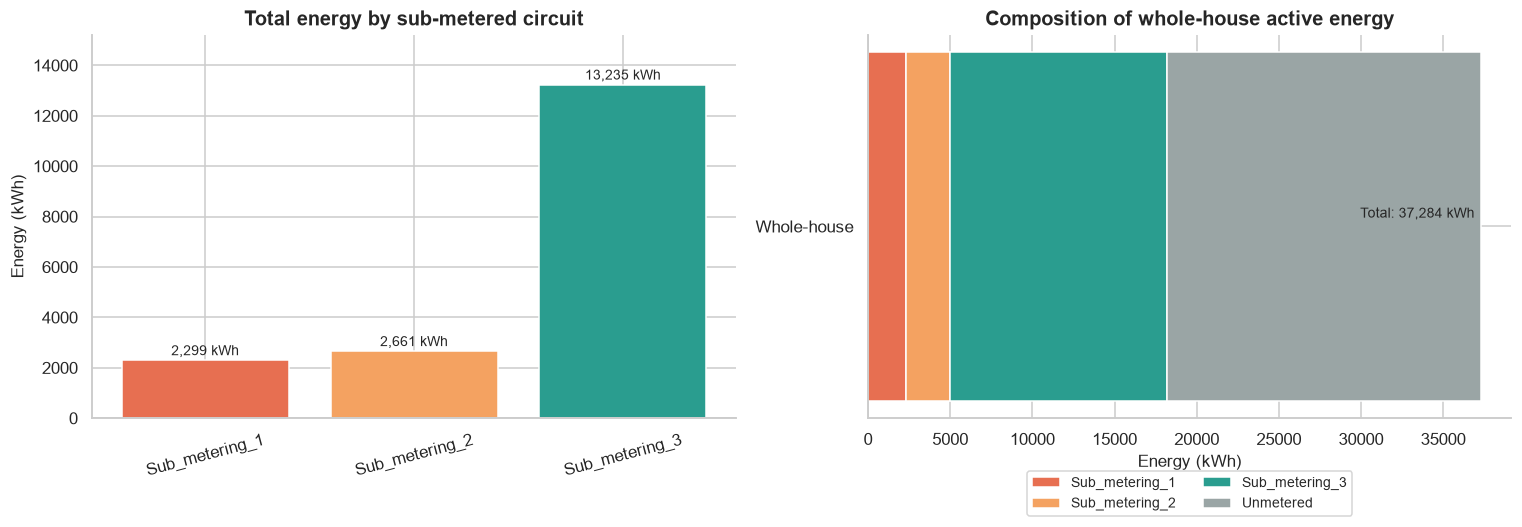

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sub_colors = ["#e76f51", "#f4a261", "#2a9d8f", "#9aa5a5"]
bars = axes[0].bar(sub_kwh.index, sub_kwh.values, color=sub_colors[:3])
for bar, value in zip(bars, sub_kwh.values, strict=True):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        value + sub_kwh.max() * 0.015,
        f"{value:,.0f} kWh",
        ha="center",
        fontsize=9,
    )
axes[0].set_ylim(0, sub_kwh.max() * 1.15)
axes[0].set_ylabel("Energy (kWh)")
axes[0].set_title("Total energy by sub-metered circuit")
axes[0].tick_params(axis="x", rotation=15)

components = [*sub_kwh.values, unmetered_kwh]
labels = [*SUB_METERING_COLUMNS, "Unmetered"]
left = 0.0
for value, label, color in zip(components, labels, sub_colors, strict=True):
    axes[1].barh(["Whole-house"], [value], left=left, color=color, label=label)
    left += value
axes[1].set_xlabel("Energy (kWh)")
axes[1].set_title("Composition of whole-house active energy")
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, fontsize=9)
axes[1].text(
    global_kwh * 0.99,
    0.02,
    f"Total: {global_kwh:,.0f} kWh",
    ha="right",
    fontsize=9,
)

save_and_show(fig, "17_submetering_comparison.png")

**Observation.** The monitored circuits account for less than half of whole-house
active energy, so the sub-metering columns cannot be treated as a complete
breakdown. The remainder is unmetered consumption, not an error.

## 18. Daily Energy Consumption Trends

Daily energy is the sum of `Global_active_power / 60` over the available minute
readings. Missing minutes are excluded, never filled with zero, so days with
missing readings are conservative lower bounds.

Calendar days:              1,442
Days with data:             1,433
Days with no valid reading: 9
Days below 90% coverage:    22
First day:                  2006-12-16
Last day:                   2010-11-26
Mean daily energy:          26.02 kWh
Maximum daily energy:       79.56 kWh on 2006-12-23
Minimum daily energy:       0.24 kWh on 2009-06-13 (30 valid minutes, 2.08% coverage)


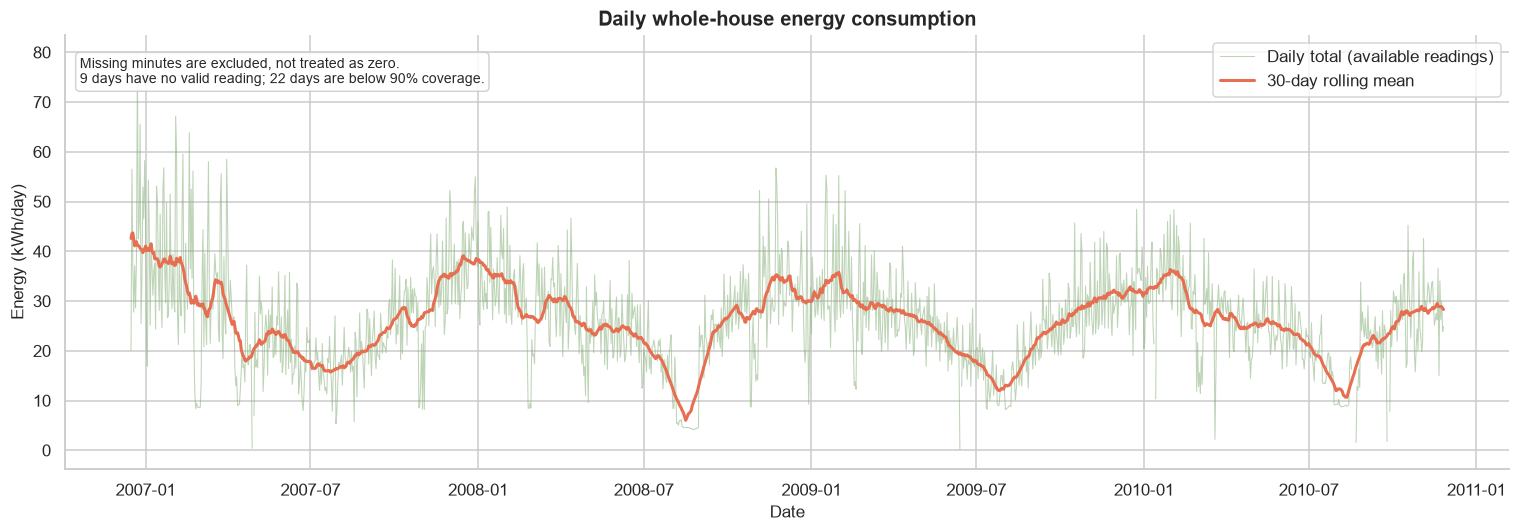

In [19]:
valid_time_mask = timestamps.notna()
energy = pd.Series(
    df.loc[valid_time_mask, "Global_active_power"].to_numpy() / 60.0,
    index=pd.DatetimeIndex(timestamps.loc[valid_time_mask]),
    name="energy_kwh",
)

daily_kwh = energy.resample("D").sum(min_count=1)
daily_rolling = daily_kwh.rolling(30, min_periods=7, center=True).mean()
daily_valid = energy.resample("D").count()
daily_slots = energy.resample("D").size()
daily_coverage = daily_valid / daily_slots * 100
max_day = daily_kwh.idxmax()
min_day = daily_kwh.idxmin()

print(f"Calendar days:              {len(daily_kwh):,}")
print(f"Days with data:             {int(daily_kwh.notna().sum()):,}")
print(f"Days with no valid reading: {int(daily_kwh.isna().sum()):,}")
print(f"Days below 90% coverage:    {int((daily_coverage < 90).sum()):,}")
print(f"First day:                  {daily_kwh.first_valid_index().date()}")
print(f"Last day:                   {daily_kwh.last_valid_index().date()}")
print(f"Mean daily energy:          {daily_kwh.mean():,.2f} kWh")
print(f"Maximum daily energy:       {daily_kwh.max():,.2f} kWh on {max_day.date()}")
print(
    f"Minimum daily energy:       {daily_kwh.min():,.2f} kWh on {min_day.date()} "
    f"({int(daily_valid.loc[min_day]):,} valid minutes, "
    f"{daily_coverage.loc[min_day]:.2f}% coverage)"
)

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(
    daily_kwh.index,
    daily_kwh.to_numpy(),
    color="#8ab17d",
    linewidth=0.7,
    alpha=0.55,
    label="Daily total (available readings)",
)
ax.plot(
    daily_rolling.index,
    daily_rolling.to_numpy(),
    color="#e76f51",
    linewidth=2,
    label="30-day rolling mean",
)
ax.set_xlabel("Date")
ax.set_ylabel("Energy (kWh/day)")
ax.set_title("Daily whole-house energy consumption")
ax.legend(loc="upper right")
ax.text(
    0.01,
    0.95,
    f"Missing minutes are excluded, not treated as zero.\n"
    f"{int(daily_kwh.isna().sum()):,} days have no valid reading; "
    f"{int((daily_coverage < 90).sum()):,} days are below 90% coverage.",
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=9,
    bbox={"boxstyle": "round", "facecolor": "white", "alpha": 0.85, "edgecolor": "#cccccc"},
)
save_and_show(fig, "18_daily_energy_trend.png")

## 19. Monthly Energy Consumption Trends

Monthly totals are shown as bars. The first month (December 2006) and last month
(November 2010) are partial calendar months, so their bars must not be compared
directly with full months.

Months with data:       48
Maximum monthly energy: 1,210.07 kWh in 2007-12


,Energy (kWh),Coverage (%)
2006-12-01,696.8900,99.9818
2007-01-01,"1,150.2000",99.9955
2007-02-01,941.4800,99.9950
2010-09-01,605.1600,87.8773
2010-10-01,865.5500,99.9978
2010-11-01,743.3100,100.0000


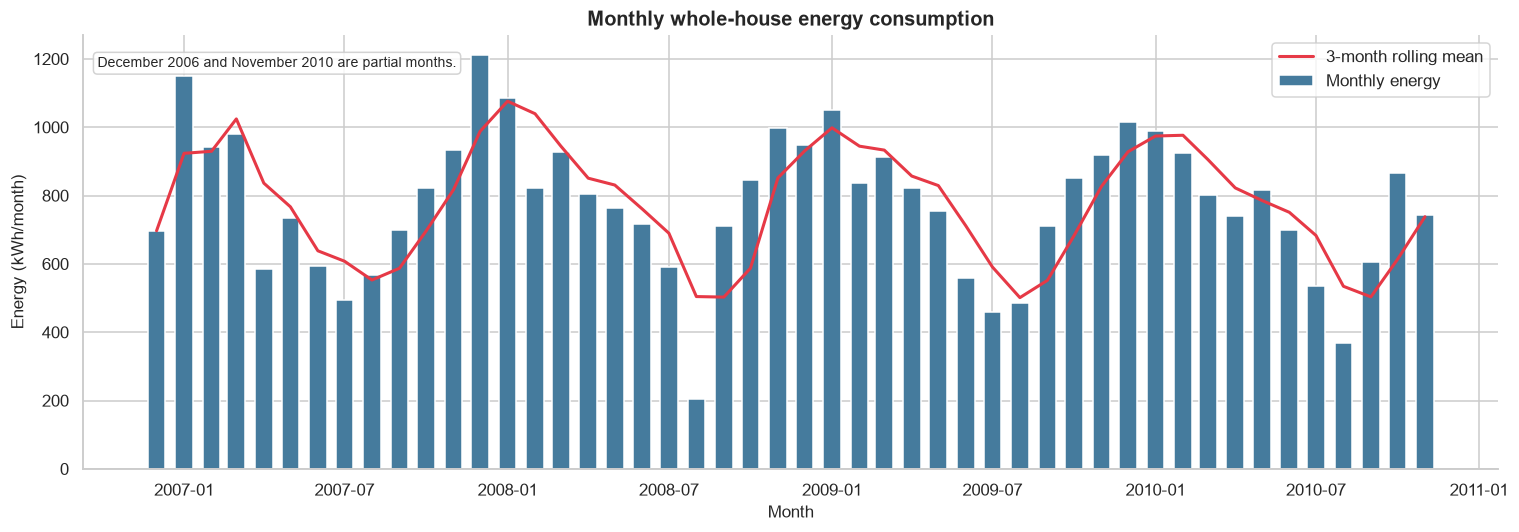

In [20]:
monthly_kwh = energy.resample("MS").sum(min_count=1)
monthly_valid = energy.resample("MS").count()
monthly_slots = energy.resample("MS").size()
monthly_coverage = (monthly_valid / monthly_slots * 100).rename("Coverage (%)")

print(f"Months with data:       {int(monthly_kwh.notna().sum()):,}")
print(f"Maximum monthly energy: {monthly_kwh.max():,.2f} kWh in {monthly_kwh.idxmax():%Y-%m}")

monthly_table = pd.DataFrame(
    {
        "Energy (kWh)": monthly_kwh.round(2),
        "Coverage (%)": monthly_coverage.round(4),
    }
)
display(pd.concat([monthly_table.head(3), monthly_table.tail(3)]))

fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(
    monthly_kwh.index,
    monthly_kwh.to_numpy(),
    width=20,
    color="#457b9d",
    edgecolor="white",
    label="Monthly energy",
)
ax.plot(
    monthly_kwh.index,
    monthly_kwh.rolling(3, min_periods=1).mean().to_numpy(),
    color="#e63946",
    linewidth=2,
    label="3-month rolling mean",
)
ax.set_xlabel("Month")
ax.set_ylabel("Energy (kWh/month)")
ax.set_title("Monthly whole-house energy consumption")
ax.legend(loc="upper right")
ax.text(
    0.01,
    0.95,
    "December 2006 and November 2010 are partial months.",
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=9,
    bbox={"boxstyle": "round", "facecolor": "white", "alpha": 0.85, "edgecolor": "#cccccc"},
)
save_and_show(fig, "19_monthly_energy_trend.png")

## 20. Hourly Energy Consumption Patterns

The average and median active power for each hour of the local day show the
household's daily routine. Averaging valid readings avoids treating missing
minutes as zero.

,Mean kW,Median kW
0,0.6594,0.3660
1,0.5393,0.3280
2,0.4806,0.3200
3,0.4449,0.3140
4,0.4438,0.3120
5,0.4537,0.3100
6,0.7916,0.3500
7,1.5022,1.5020
8,1.4610,1.4100
9,1.3316,1.3600


Peak mean hour: 20:00 at 1.899 kW


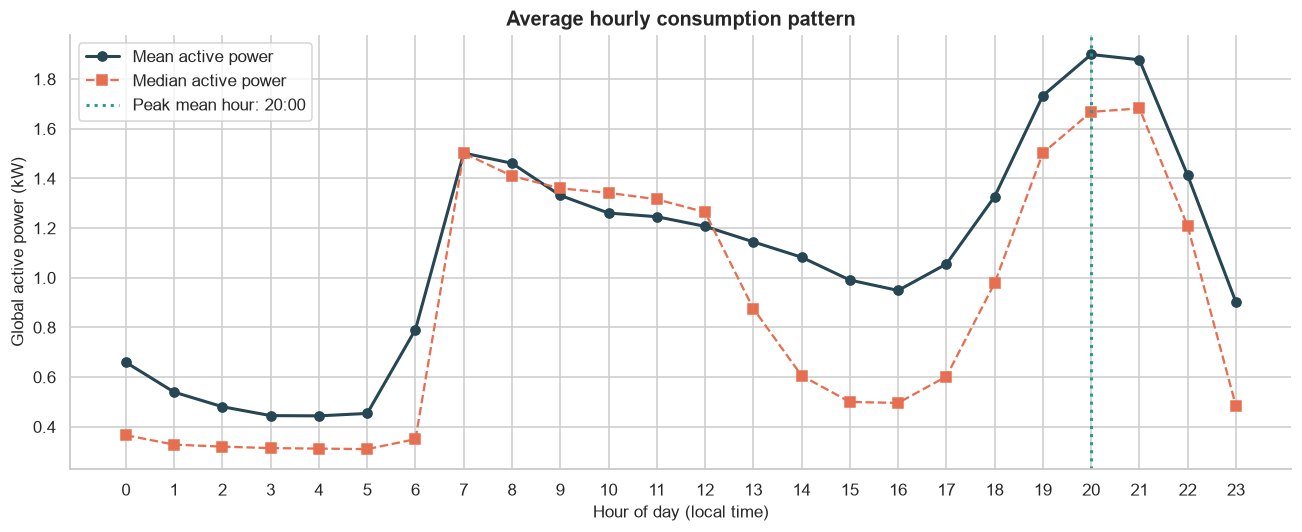

In [21]:
hourly_stats = pd.DataFrame(
    {
        "Mean kW": active.groupby(timestamps.dt.hour).mean(),
        "Median kW": active.groupby(timestamps.dt.hour).median(),
    }
)
display(hourly_stats.round(4))

peak_hour = int(hourly_stats["Mean kW"].idxmax())
print(f"Peak mean hour: {peak_hour:02d}:00 at {hourly_stats.loc[peak_hour, 'Mean kW']:.3f} kW")

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(
    hourly_stats.index,
    hourly_stats["Mean kW"],
    marker="o",
    linewidth=2,
    color="#264653",
    label="Mean active power",
)
ax.plot(
    hourly_stats.index,
    hourly_stats["Median kW"],
    marker="s",
    linewidth=1.5,
    linestyle="--",
    color="#e76f51",
    label="Median active power",
)
ax.axvline(
    peak_hour,
    color="#2a9d8f",
    linestyle=":",
    linewidth=2,
    label=f"Peak mean hour: {peak_hour:02d}:00",
)
ax.set_xticks(range(24))
ax.set_xlabel("Hour of day (local time)")
ax.set_ylabel("Global active power (kW)")
ax.set_title("Average hourly consumption pattern")
ax.legend(loc="upper left")
save_and_show(fig, "20_hourly_consumption_pattern.png")

## 21. Correlation Analysis

The heatmap reports pairwise Pearson correlations between the seven numeric
columns using all pairwise-valid readings. Correlation describes association, not
causation, and does not imply that any variable should be dropped.

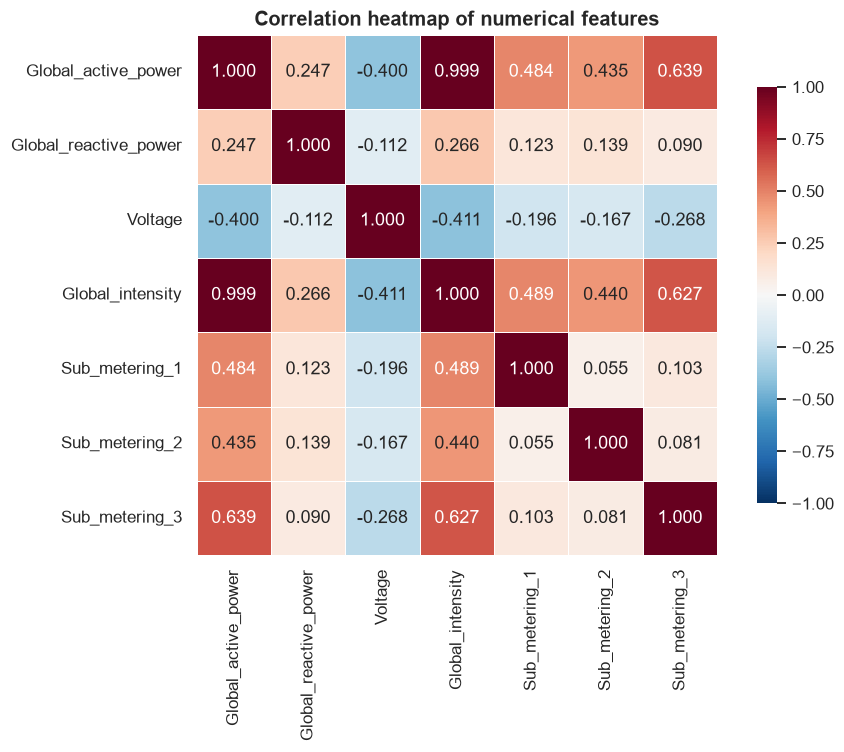

Strongest absolute correlation: Global_active_power vs Global_intensity = 0.9989


In [22]:
corr = df[NUMERIC_COLUMNS].corr()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(
    corr,
    annot=True,
    fmt=".3f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8},
    ax=ax,
)
ax.set_title("Correlation heatmap of numerical features")
save_and_show(fig, "21_correlation_heatmap.png")

corr_values = corr.to_numpy().copy()
np.fill_diagonal(corr_values, np.nan)
flat_index = int(np.nanargmax(np.abs(corr_values)))
row, col = np.unravel_index(flat_index, corr_values.shape)
print(
    "Strongest absolute correlation: "
    f"{corr.index[row]} vs {corr.columns[col]} = {corr_values[row, col]:.4f}"
)

## 22. Key Findings

In [23]:
daily_peak_date = daily_kwh.idxmax().strftime("%Y-%m-%d")
monthly_peak_month = monthly_kwh.idxmax().strftime("%Y-%m")
strongest_pair = f"{corr.index[row]} and {corr.columns[col]}"
submetered_share = sub_kwh.sum() / global_kwh * 100

findings = f"""
### What the data shows

- **Scale and coverage.** The file contains **{len(df):,} records** and
  **{df.shape[1]} columns**, spanning **{first_ts:%Y-%m-%d}** to
  **{last_ts:%Y-%m-%d}**. The valid timestamps cover **{grid_coverage:.2f}%** of the
  ideal one-minute grid.
- **Missing data.** There are **{int(df.isna().sum().sum()):,} missing cells**
  across seven measurement columns. All **{rows_all_numeric_missing:,}** affected
  rows are missing every measurement at once; no measurement is filled or treated
  as zero.
- **Daily coverage.** **{int(daily_kwh.isna().sum()):,} calendar days** have no valid
  measurement, and **{int((daily_coverage < 90).sum()):,} days** have less than 90%
  coverage, so sparse days produce conservative daily totals.
- **Duplicates and timestamps.** Complete duplicate rows: **{duplicate_rows:,}**.
  Duplicate valid timestamps: **{duplicate_timestamps:,}**. Invalid timestamps:
  **{invalid_timestamps:,}**.
- **Demand.** Mean active power is **{active_mean:.3f} kW** and the median is
  **{active_median:.3f} kW**, with a maximum of **{active_valid.max():.3f} kW**.
  The distribution is right-skewed (skewness **{active_valid.skew():.3f}**).
- **Voltage.** Voltage ranges from **{voltage_valid.min():.2f} V** to
  **{voltage_valid.max():.2f} V**, with a mean of **{voltage_valid.mean():.2f} V**.
- **Energy.** Available readings total **{global_kwh:,.2f} kWh** of whole-house
  active energy. The three sub-meters account for **{sub_kwh.sum():,.2f} kWh**,
  or **{submetered_share:.2f}%** of the whole-house total.
- **Daily peak.** The highest daily total is **{daily_kwh.max():,.2f} kWh** on
  **{daily_peak_date}**.
- **Monthly peak.** The highest monthly total is **{monthly_kwh.max():,.2f} kWh**
  in **{monthly_peak_month}** (monthly totals include partial boundary months).
- **Hourly pattern.** Mean demand peaks at **{peak_hour:02d}:00**, at
  **{hourly_stats.loc[peak_hour, 'Mean kW']:.3f} kW**.
- **Correlation.** The strongest absolute correlation is **{strongest_pair}**
  (**{corr_values[row, col]:.3f}**).

### Data-quality implications

- Block missingness means daily and monthly energy totals are conservative when
  missing readings are excluded.
- Sub-metering is not a complete decomposition of whole-house consumption.
- Local wall-clock timestamps need an explicit timezone and daylight-saving
  policy before storage or forecasting.
- Zero sub-metering values are real idle periods and must stay distinct from
  missing values.
"""

display(Markdown(findings))


### What the data shows

- **Scale and coverage.** The file contains **2,075,259 records** and
  **9 columns**, spanning **2006-12-16** to
  **2010-11-26**. The valid timestamps cover **100.00%** of the
  ideal one-minute grid.
- **Missing data.** There are **181,853 missing cells**
  across seven measurement columns. All **25,979** affected
  rows are missing every measurement at once; no measurement is filled or treated
  as zero.
- **Daily coverage.** **9 calendar days** have no valid
  measurement, and **22 days** have less than 90%
  coverage, so sparse days produce conservative daily totals.
- **Duplicates and timestamps.** Complete duplicate rows: **0**.
  Duplicate valid timestamps: **0**. Invalid timestamps:
  **0**.
- **Demand.** Mean active power is **1.092 kW** and the median is
  **0.602 kW**, with a maximum of **11.122 kW**.
  The distribution is right-skewed (skewness **1.786**).
- **Voltage.** Voltage ranges from **223.20 V** to
  **254.15 V**, with a mean of **240.84 V**.
- **Energy.** Available readings total **37,283.75 kWh** of whole-house
  active energy. The three sub-meters account for **18,195.33 kWh**,
  or **48.80%** of the whole-house total.
- **Daily peak.** The highest daily total is **79.56 kWh** on
  **2006-12-23**.
- **Monthly peak.** The highest monthly total is **1,210.07 kWh**
  in **2007-12** (monthly totals include partial boundary months).
- **Hourly pattern.** Mean demand peaks at **20:00**, at
  **1.899 kW**.
- **Correlation.** The strongest absolute correlation is **Global_active_power and Global_intensity**
  (**0.999**).

### Data-quality implications

- Block missingness means daily and monthly energy totals are conservative when
  missing readings are excluded.
- Sub-metering is not a complete decomposition of whole-house consumption.
- Local wall-clock timestamps need an explicit timezone and daylight-saving
  policy before storage or forecasting.
- Zero sub-metering values are real idle periods and must stay distinct from
  missing values.


## 23. Conclusion

Phase 2 confirms that the UCI household dataset is a credible, minute-level
foundation for EcoPulse AI. It provides four years of real electricity
measurements with complete timestamps, a known and well-defined missingness
pattern, and enough seasonal and daily structure to support later forecasting and
anomaly-detection work.

The main constraint is data quality, not dataset size. Approximately 1.25% of the
measurement cells are missing in whole-reading blocks, the timestamps are local
civil time without an offset, and sub-metering covers less than half of
whole-house energy. This notebook deliberately documents those issues instead of
fixing them.

Phase 3 should build the ETL layer that parses and normalises timestamps to UTC,
preserves a missing-value mask, validates physical ranges, derives kWh explicitly,
and stores curated data reproducibly in PostgreSQL and Parquet. No cleaning,
imputation, outlier removal, forecasting, or anomaly detection was performed in
this phase.